# Homicide Reports: Cleaned Data and Analysis
Loads `database.csv`, applies the cleaning rules from `EDA_Project.ipynb`, saves `cleaned_database.csv`, then reproduces the plots on the cleaned data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 60)

df = pd.read_csv("database.csv", low_memory=False)
print("Raw shape:", df.shape)

Raw shape: (638454, 24)


## 1. Cleaning

**Column names**

In [2]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
    .str.replace(r"[^0-9a-z]+", "_", regex=True)
)
list(df.columns)

['record_id',
 'agency_code',
 'agency_name',
 'agency_type',
 'city',
 'state',
 'year',
 'month',
 'incident',
 'crime_type',
 'crime_solved',
 'victim_sex',
 'victim_age',
 'victim_race',
 'victim_ethnicity',
 'perpetrator_sex',
 'perpetrator_age',
 'perpetrator_race',
 'perpetrator_ethnicity',
 'relationship',
 'weapon',
 'victim_count',
 'perpetrator_count',
 'record_source']

**Location, year and month number**

In [3]:
df["location"] = (
    df["city"].astype("string").str.strip()
    + ", "
    + df["state"].astype("string").str.strip()
)

month_map = {
    "January": 1, "February": 2, "March": 3, "April": 4,
    "May": 5, "June": 6, "July": 7, "August": 8,
    "September": 9, "October": 10, "November": 11, "December": 12,
}
df["month_num"] = df["month"].map(month_map).astype("Int64")
df["year"] = pd.to_numeric(df["year"], errors="coerce").astype("Int64")

**Ages and counts**
- Ages are converted to numbers; non-numeric values become missing.
- Victim age of 998 or more (unknown code) becomes missing.
- Perpetrator age below 8 (including 0, the code for an unknown perpetrator) becomes missing.
- Ages and counts are stored as nullable integers.

In [4]:
for col in ["victim_age", "perpetrator_age"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df.loc[df["victim_age"] >= 998, "victim_age"] = np.nan
df.loc[df["perpetrator_age"] < 8, "perpetrator_age"] = np.nan

for col in ["victim_age", "perpetrator_age", "victim_count", "perpetrator_count"]:
    df[col] = pd.to_numeric(df[col], errors="coerce").round().astype("Int64")

**Check the result**

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 638454 entries, 0 to 638453
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype 
---  ------                 --------------   ----- 
 0   record_id              638454 non-null  int64 
 1   agency_code            638454 non-null  object
 2   agency_name            638454 non-null  object
 3   agency_type            638454 non-null  object
 4   city                   638454 non-null  object
 5   state                  638454 non-null  object
 6   year                   638454 non-null  Int64 
 7   month                  638454 non-null  object
 8   incident               638454 non-null  int64 
 9   crime_type             638454 non-null  object
 10  crime_solved           638454 non-null  object
 11  victim_sex             638454 non-null  object
 12  victim_age             637480 non-null  Int64 
 13  victim_race            638454 non-null  object
 14  victim_ethnicity       638454 non-null  object
 15  

In [6]:
df.isnull().sum()

record_id                     0
agency_code                   0
agency_name                   0
agency_type                   0
city                          0
state                         0
year                          0
month                         0
incident                      0
crime_type                    0
crime_solved                  0
victim_sex                    0
victim_age                  974
victim_race                   0
victim_ethnicity              0
perpetrator_sex               0
perpetrator_age          216552
perpetrator_race              0
perpetrator_ethnicity         0
relationship                  0
weapon                        0
victim_count                  0
perpetrator_count             0
record_source                 0
location                      0
month_num                     0
dtype: int64

In [7]:
summary = pd.Series({
    "Records": len(df),
    "Years": f"{df['year'].min()} to {df['year'].max()}",
    "States": df["state"].nunique(),
    "Solved (Yes)": int((df["crime_solved"] == "Yes").sum()),
    "Unsolved (No)": int((df["crime_solved"] == "No").sum()),
    "Solved rate (%)": round((df["crime_solved"] == "Yes").mean() * 100, 2),
    "Valid perpetrator ages": int(df["perpetrator_age"].notna().sum()),
    "Valid victim ages": int(df["victim_age"].notna().sum()),
})
summary

Records                         638454
Years                     1980 to 2014
States                              51
Solved (Yes)                    448172
Unsolved (No)                   190282
Solved rate (%)                   70.2
Valid perpetrator ages          421902
Valid victim ages               637480
dtype: object

In [8]:
try:
    df.to_csv("cleaned_database.csv", index=False)
    print("Saved cleaned_database.csv with", df.shape[0], "rows and", df.shape[1], "columns")
except PermissionError:
    print("Could not save: close cleaned_database.csv (for example in Excel) and run this cell again.")

Saved cleaned_database.csv with 638454 rows and 26 columns


## 2. Missing data

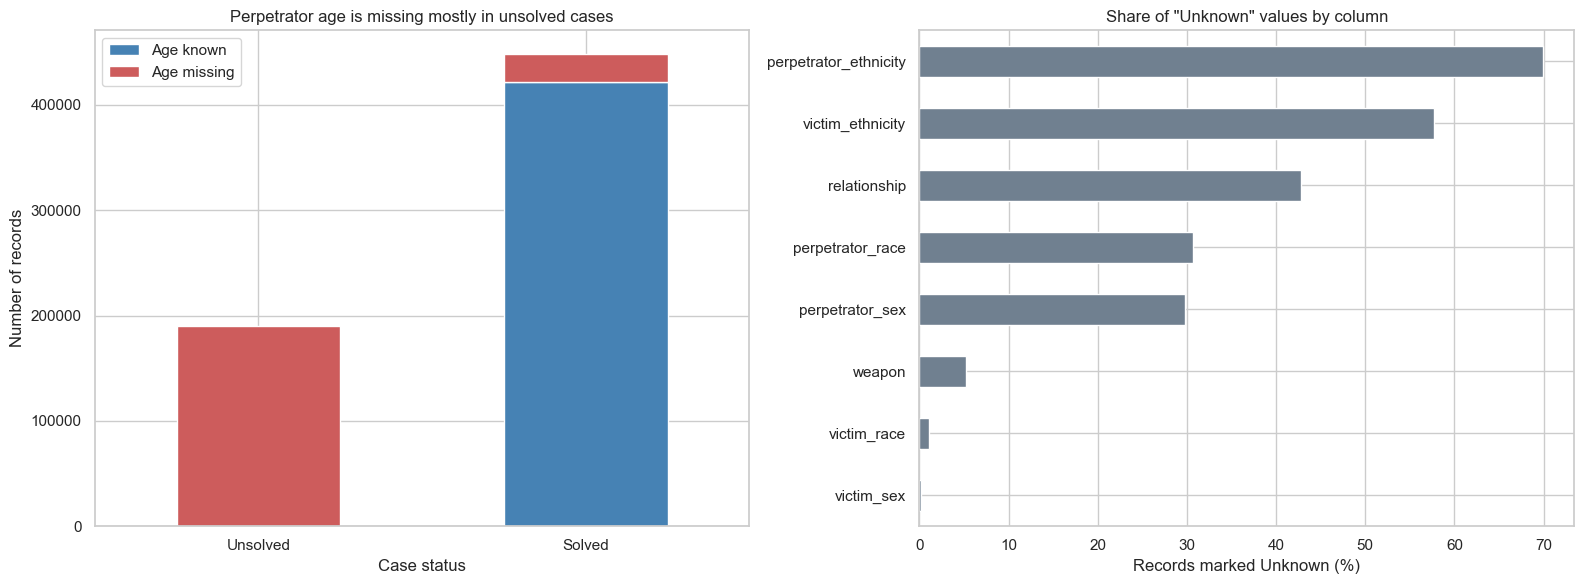

              Age known  Age missing
crime_solved                        
No                  634       189648
Yes              421268        26904
Perpetrator age missing: 216552 (33.9%)
Victim age missing: 974 (0.15%)


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Perpetrator age: missing vs known, by case status
age_status = pd.crosstab(df["crime_solved"], df["perpetrator_age"].isna())
age_status.columns = ["Age known", "Age missing"]
age_status.rename(index={"Yes": "Solved", "No": "Unsolved"}).plot(
    kind="bar", stacked=True, ax=axes[0], color=["steelblue", "indianred"], rot=0
)
axes[0].set_title("Perpetrator age is missing mostly in unsolved cases")
axes[0].set_xlabel("Case status")
axes[0].set_ylabel("Number of records")

# Share of "Unknown" values per column
cols = ["perpetrator_ethnicity", "victim_ethnicity", "relationship",
        "perpetrator_race", "perpetrator_sex", "weapon", "victim_race", "victim_sex"]
unknown_pct = pd.Series({c: (df[c] == "Unknown").mean() * 100 for c in cols}).sort_values()
unknown_pct.plot(kind="barh", ax=axes[1], color="slategray")
axes[1].set_title('Share of "Unknown" values by column')
axes[1].set_xlabel("Records marked Unknown (%)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()
print(age_status)
print("Perpetrator age missing:", df["perpetrator_age"].isna().sum(), f"({df['perpetrator_age'].isna().mean()*100:.1f}%)")
print("Victim age missing:", df["victim_age"].isna().sum(), f"({df['victim_age'].isna().mean()*100:.2f}%)")

**Insight:** A third of perpetrator ages (216,552 records) are missing, and almost all of them are unsolved cases: 189,648 of the 190,282 unsolved records have no age. That makes sense, since nobody was identified. Another 26,904 solved cases have an age of 0 or blank, about 6% of solved cases. Victim age is missing in only 974 records. Ethnicity is unknown for about 70% of perpetrators and 58% of victims, so it is too patchy to rely on.

## 3. Plots

### 3.1 Homicide records per year

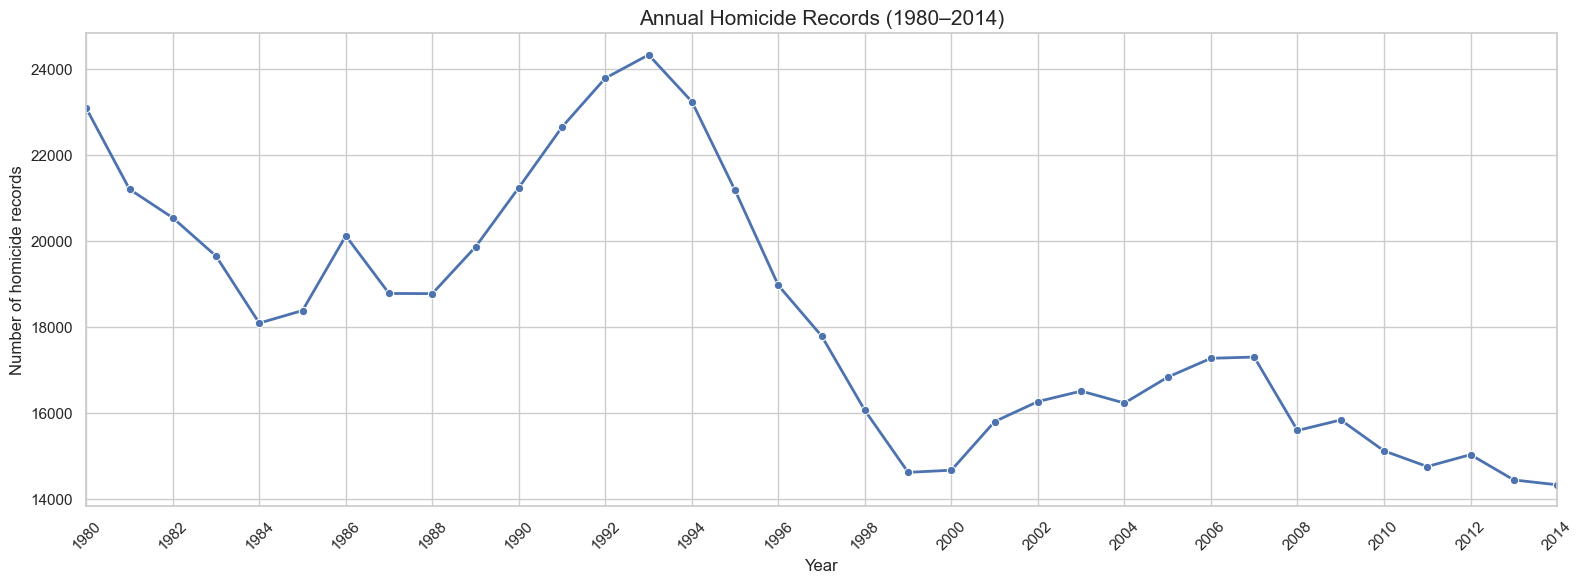

In [10]:
yearly = df.groupby("year").size()

plt.figure(figsize=(16, 6))
sns.lineplot(x=yearly.index, y=yearly.values, marker="o", linewidth=2)
plt.title("Annual Homicide Records (1980–2014)", fontsize=15)
plt.xlabel("Year")
plt.ylabel("Number of homicide records")
plt.xticks(range(1980, 2015, 2), rotation=45)
plt.xlim(1980, 2014)
plt.tight_layout()
plt.show()

**Insight:** Homicide records went from 23,092 in 1980 up to a peak of 24,335 in 1993, then dropped quickly to 14,621 by 1999. They stayed low after that, and 2014 is the lowest year at 14,331. The 2010–2014 average is about 36% below the 1990–1994 average.

### 3.2 Monthly records by year

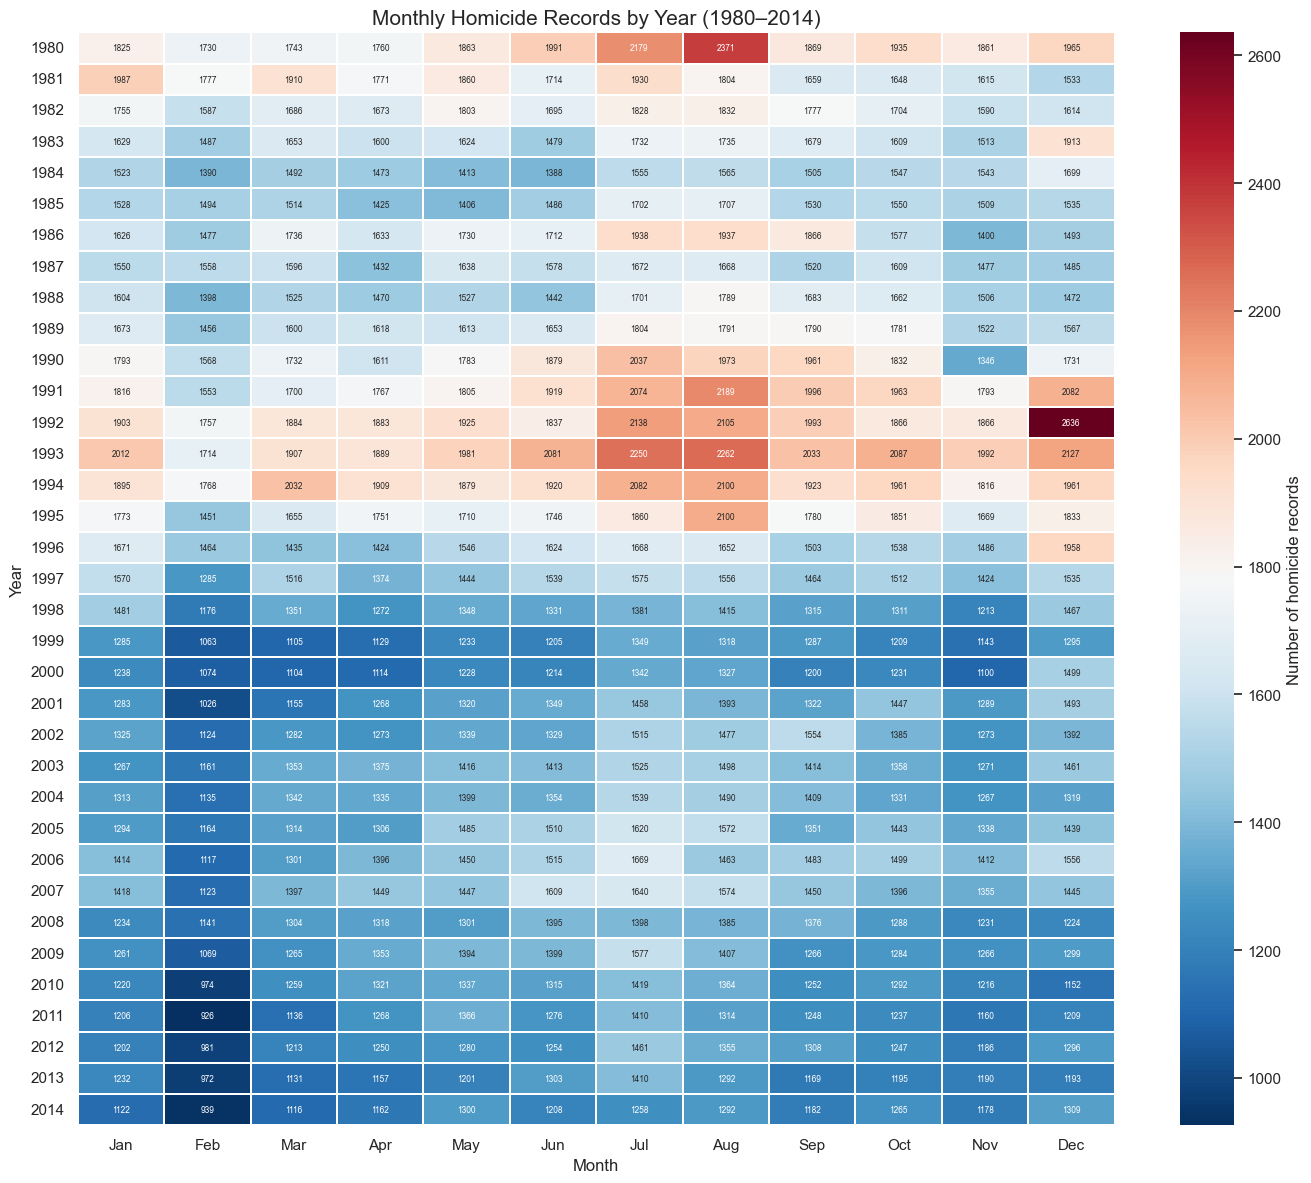

month_num
Jan    52928
Feb    46079
Mar    51444
Apr    51209
May    53394
Jun    53662
Jul    58696
Aug    58072
Sep    54117
Oct    53650
Nov    50016
Dec    55187
dtype: int64


In [11]:
month_labels = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

heat = pd.crosstab(df["year"], df["month_num"]).reindex(
    index=range(1980, 2015), columns=range(1, 13), fill_value=0
)
heat.columns = month_labels

plt.figure(figsize=(14, 12))
sns.heatmap(heat, cmap="RdBu_r", annot=True, fmt="d", linewidths=0.2,
            annot_kws={"size": 6}, cbar_kws={"label": "Number of homicide records"})
plt.title("Monthly Homicide Records by Year (1980–2014)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

print(df.groupby("month_num").size().rename(index=dict(enumerate(month_labels, 1))))

**Insight:** December 1992 is the busiest month on record (2,636 records) and February 2011 the quietest (926). Most months are high from the early 1980s through about 1994, then drop from the mid-1990s. Across all years, July (58,696) and August (58,072) have the most records and February the fewest (46,079), though February is also the shortest month.

### 3.3 Monthly records scaled 0–10 (all states combined)

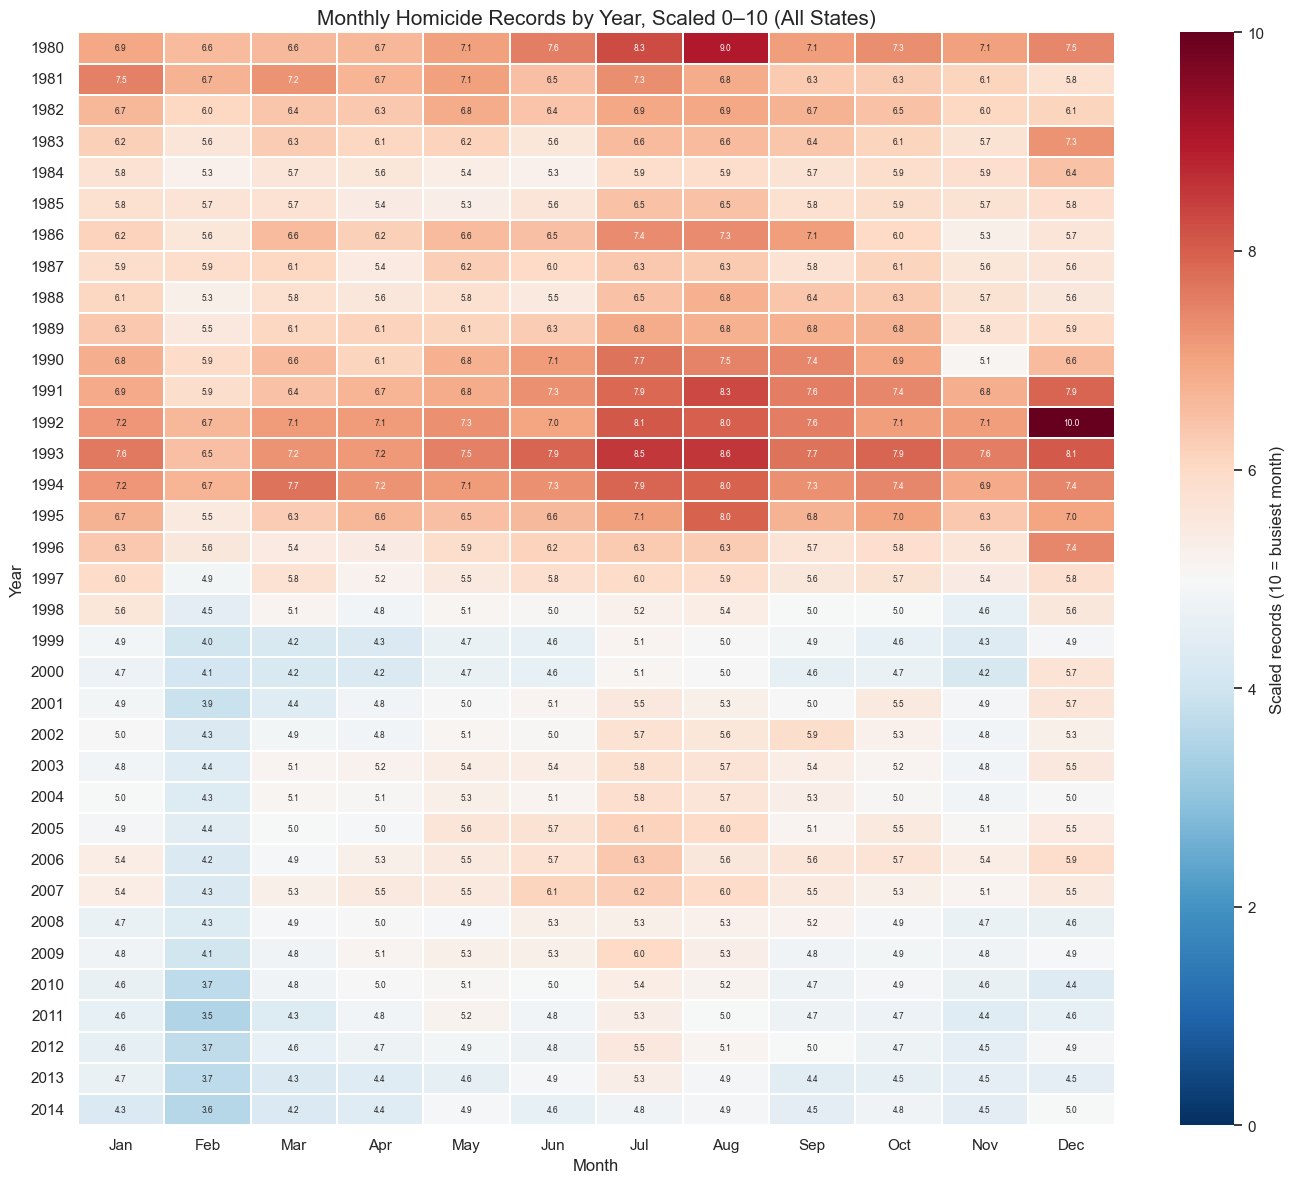

In [12]:
scaled = heat / heat.to_numpy().max() * 10

plt.figure(figsize=(14, 12))
sns.heatmap(scaled, cmap="RdBu_r", annot=True, fmt=".1f", linewidths=0.2,
            annot_kws={"size": 6}, vmin=0, vmax=10,
            cbar_kws={"label": "Scaled records (10 = busiest month)"})
plt.title("Monthly Homicide Records by Year, Scaled 0–10 (All States)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

**Insight:** Same picture as the chart above, scaled so that December 1992 equals 10. The quietest month, February 2011, comes out at 3.5, so the busiest month had roughly 2.8 times as many records.

### 3.4 Monthly records by state (each state scaled 0–10)

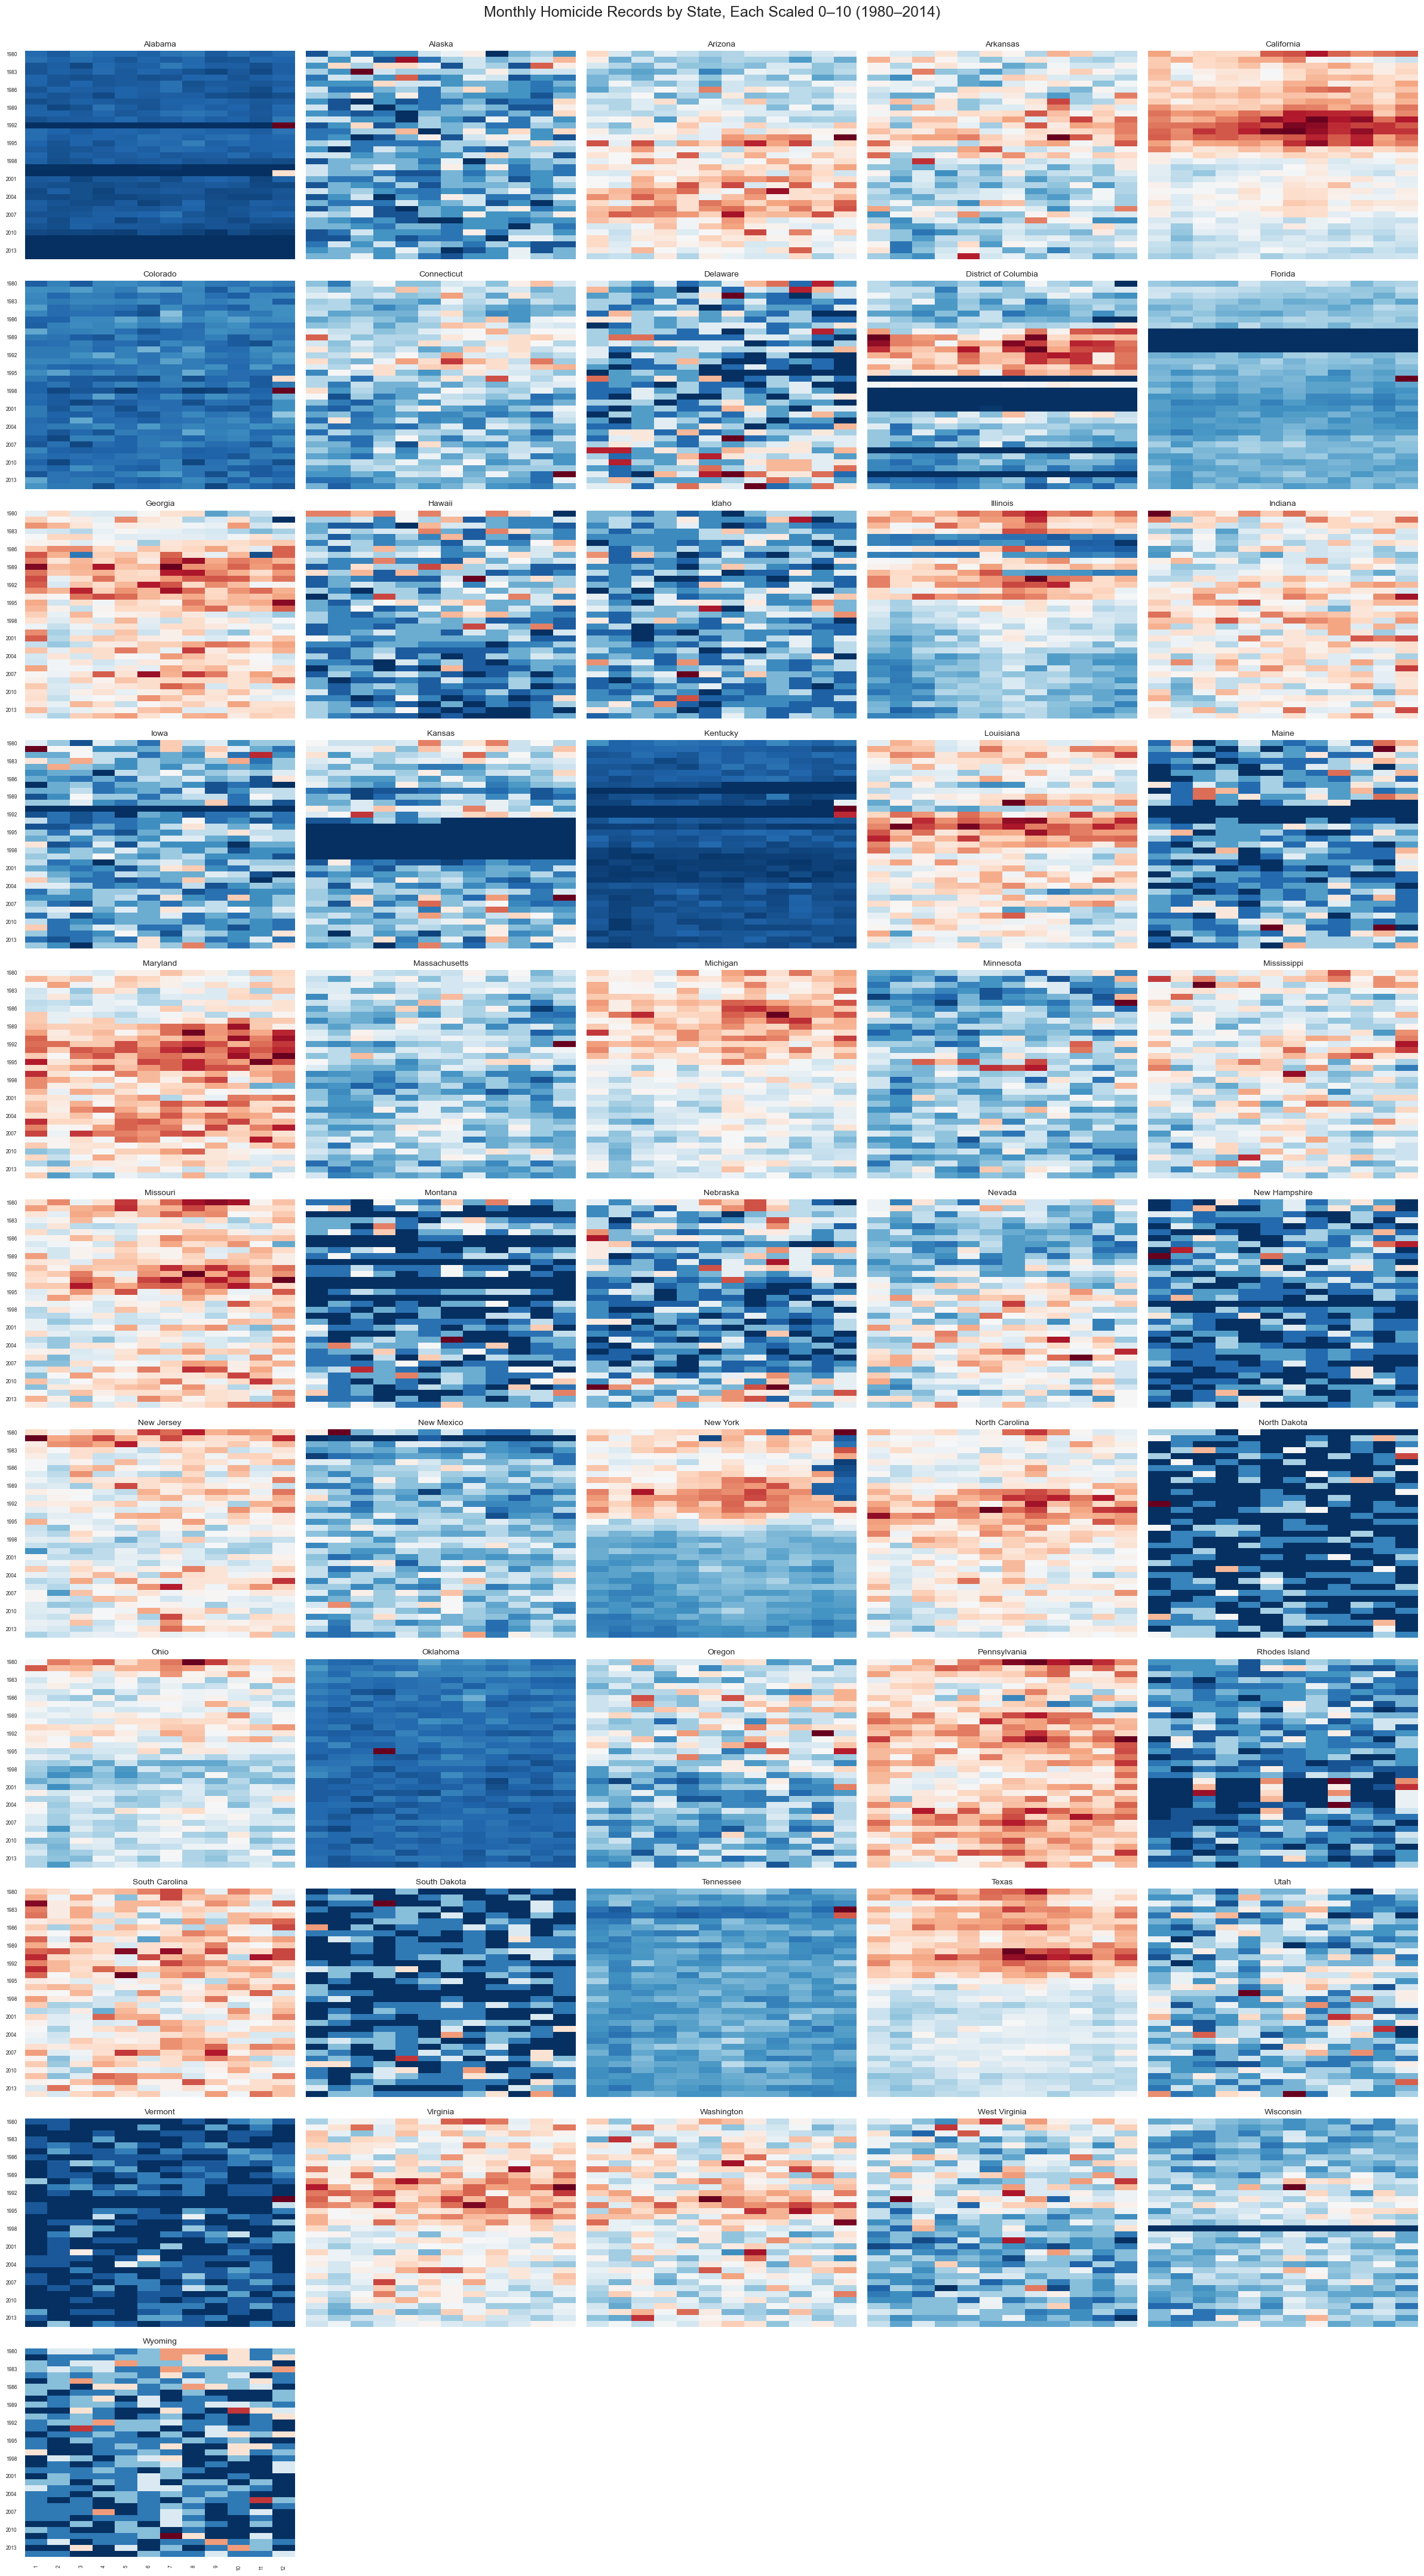

In [13]:
states = sorted(df["state"].dropna().unique())
ncols = 5
nrows = math.ceil(len(states) / ncols)

fig, axes = plt.subplots(nrows, ncols, figsize=(24, nrows * 4), sharex=True, sharey=True)
axes = axes.flatten()

for i, state in enumerate(states):
    s = df[df["state"] == state]
    h = pd.crosstab(s["year"], s["month_num"]).reindex(
        index=range(1980, 2015), columns=range(1, 13), fill_value=0
    )
    h = h / h.to_numpy().max() * 10
    sns.heatmap(h, ax=axes[i], cmap="RdBu_r", vmin=0, vmax=10, cbar=False)
    axes[i].set_title(state, fontsize=10)
    axes[i].set_xlabel("")
    axes[i].set_ylabel("")
    axes[i].tick_params(axis="x", labelsize=6, rotation=90)
    axes[i].tick_params(axis="y", labelsize=6)

for i in range(len(states), len(axes)):
    fig.delaxes(axes[i])

fig.suptitle("Monthly Homicide Records by State, Each Scaled 0–10 (1980–2014)", fontsize=18)
fig.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

**Insight:** Each state is scaled to its own busiest month, so the colours show timing inside a state, not how big one state is compared with another. In New York, Texas, Michigan and California, counts are higher from 1980 until the mid-1990s and much lower from then to 2014. California, New York and Texas peaked around 1991–1993, while Michigan peaked earlier, in 1987. Comparing 1980–1994 with 1995–2014, the yearly average fell by 55% in New York (2,057 to 921), 38% in Texas (2,259 to 1,410), 31% in Michigan (989 to 680) and 30% in California (3,444 to 2,406).

Context: this lines up with the nationwide homicide decline of the 1990s. Research links that decline to several possible factors, including the end of the crack cocaine epidemic, increased policing and higher incarceration. This data cannot confirm any of them as the direct cause in these four states without further analysis.

### 3.5 Age difference between perpetrator and victim

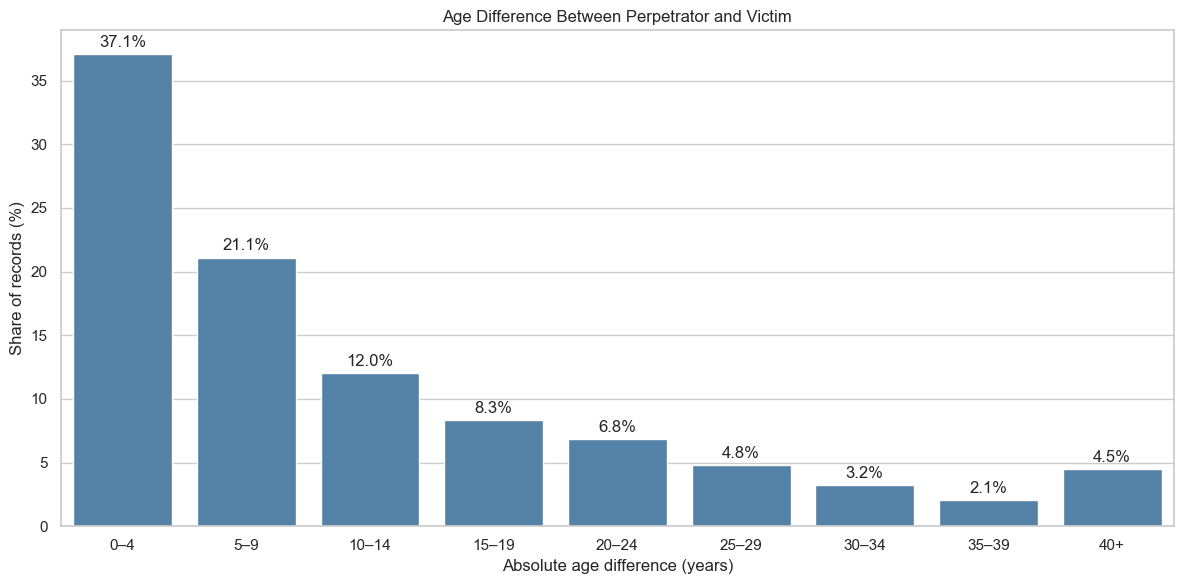

Records with both ages valid: 414,335 (64.9% of all records)


In [14]:
ages = df[
    df["perpetrator_age"].between(1, 100) & df["victim_age"].between(1, 100)
].copy()
ages["gap"] = (ages["perpetrator_age"] - ages["victim_age"]).abs()

bins = [-1, 4, 9, 14, 19, 24, 29, 34, 39, 100]
labels = ["0–4", "5–9", "10–14", "15–19", "20–24", "25–29", "30–34", "35–39", "40+"]
ages["group"] = pd.cut(ages["gap"], bins=bins, labels=labels)
gap_pct = ages["group"].value_counts(sort=False, normalize=True).mul(100)

plt.figure(figsize=(12, 6))
ax = sns.barplot(x=gap_pct.index.astype(str), y=gap_pct.values, color="steelblue")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
plt.title("Age Difference Between Perpetrator and Victim")
plt.xlabel("Absolute age difference (years)")
plt.ylabel("Share of records (%)")
plt.tight_layout()
plt.show()
print("Records with both ages valid:", f"{len(ages):,}", f"({len(ages)/len(df)*100:.1f}% of all records)")

**Insight:** Of the records where both ages are known, 37.1% have a perpetrator and victim within 4 years of each other, and 70.2% are within 14 years. The share keeps falling as the gap grows, down to 2.1% at 35–39 years. The 4.5% for 40+ looks like a rise, but that bar covers every gap from 40 to 100 years, so it can't be compared with the 5-year bars. Only 414,335 records (64.9%) have both ages, and most of them are solved cases.

### 3.6 Weapons by perpetrator sex

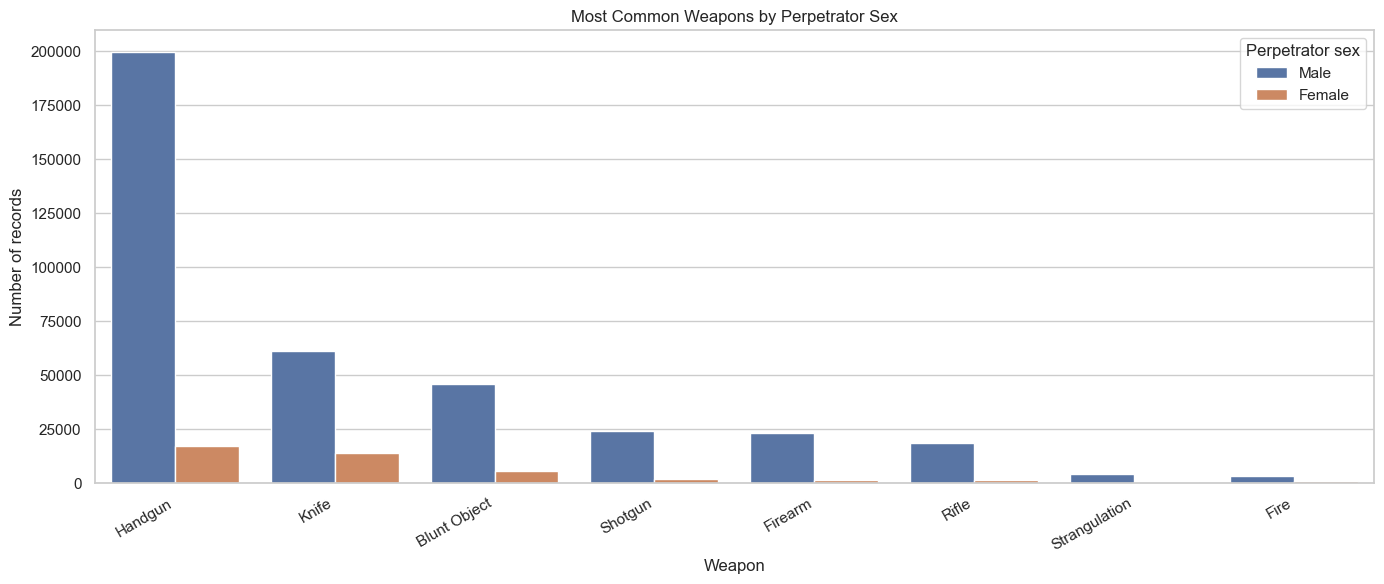

perpetrator_sex  weapon      
Female           Handgun          17107
                 Knife            13748
                 Blunt Object      5722
Male             Handgun         199776
                 Knife            61015
                 Blunt Object     45782
Name: count, dtype: int64


In [15]:
w = df[
    df["perpetrator_sex"].isin(["Male", "Female"])
    & (df["weapon"] != "Unknown")
]
top_weapons = w["weapon"].value_counts().head(8).index

plt.figure(figsize=(14, 6))
sns.countplot(data=w[w["weapon"].isin(top_weapons)], x="weapon",
              hue="perpetrator_sex", order=top_weapons, hue_order=["Male", "Female"])
plt.title("Most Common Weapons by Perpetrator Sex")
plt.xlabel("Weapon")
plt.ylabel("Number of records")
plt.xticks(rotation=30, ha="right")
plt.legend(title="Perpetrator sex")
plt.tight_layout()
plt.show()

print(w.groupby("perpetrator_sex")["weapon"].value_counts().groupby(level=0).head(3))

**Insight:** Handguns are the top weapon for both sexes: 199,776 male records and 17,107 female. The mix is different, though. For women, knives come close (13,748, which is 80% of the handgun count). For men, knives are far behind (61,015, or 31%). Women make up 10.4% of these records, but 18.4% of knife records and 24.2% of fire records. Only records with a known weapon and a male or female perpetrator are counted.

### 3.7 Perpetrator age distribution

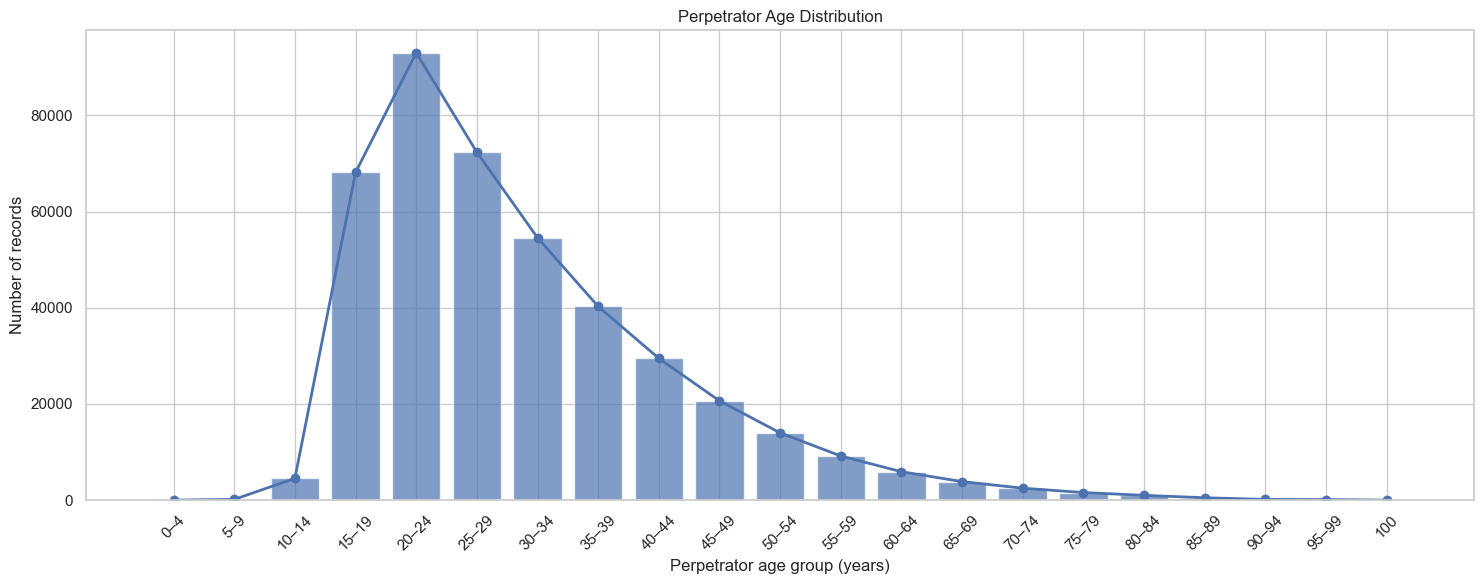

Records with a valid perpetrator age: 421,902 | median age: 27.0


In [16]:
p = df[df["perpetrator_age"].between(1, 100)].copy()
bins = list(range(0, 101, 5)) + [101]
labels = [f"{i}–{i+4}" for i in range(0, 100, 5)] + ["100"]
p["group"] = pd.cut(p["perpetrator_age"], bins=bins, labels=labels, right=False)
counts = p["group"].value_counts(sort=False).reindex(labels, fill_value=0)

plt.figure(figsize=(15, 6))
plt.bar(counts.index, counts.values, alpha=0.7)
plt.plot(counts.index, counts.values, marker="o", linewidth=2)
plt.title("Perpetrator Age Distribution")
plt.xlabel("Perpetrator age group (years)")
plt.ylabel("Number of records")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
print("Records with a valid perpetrator age:", f"{len(p):,}", "| median age:", p["perpetrator_age"].median())

**Insight:** Among the 421,902 records with a known perpetrator age, 20–24 is the biggest group (93,024 records, 22%) and the median age is 27. Ages 15–29 make up 55% of records, and under-18s about 8%. After 24 the numbers fall steadily. Unsolved cases have no age, so this only describes perpetrators who were identified.

### 3.8 Solved rate by state

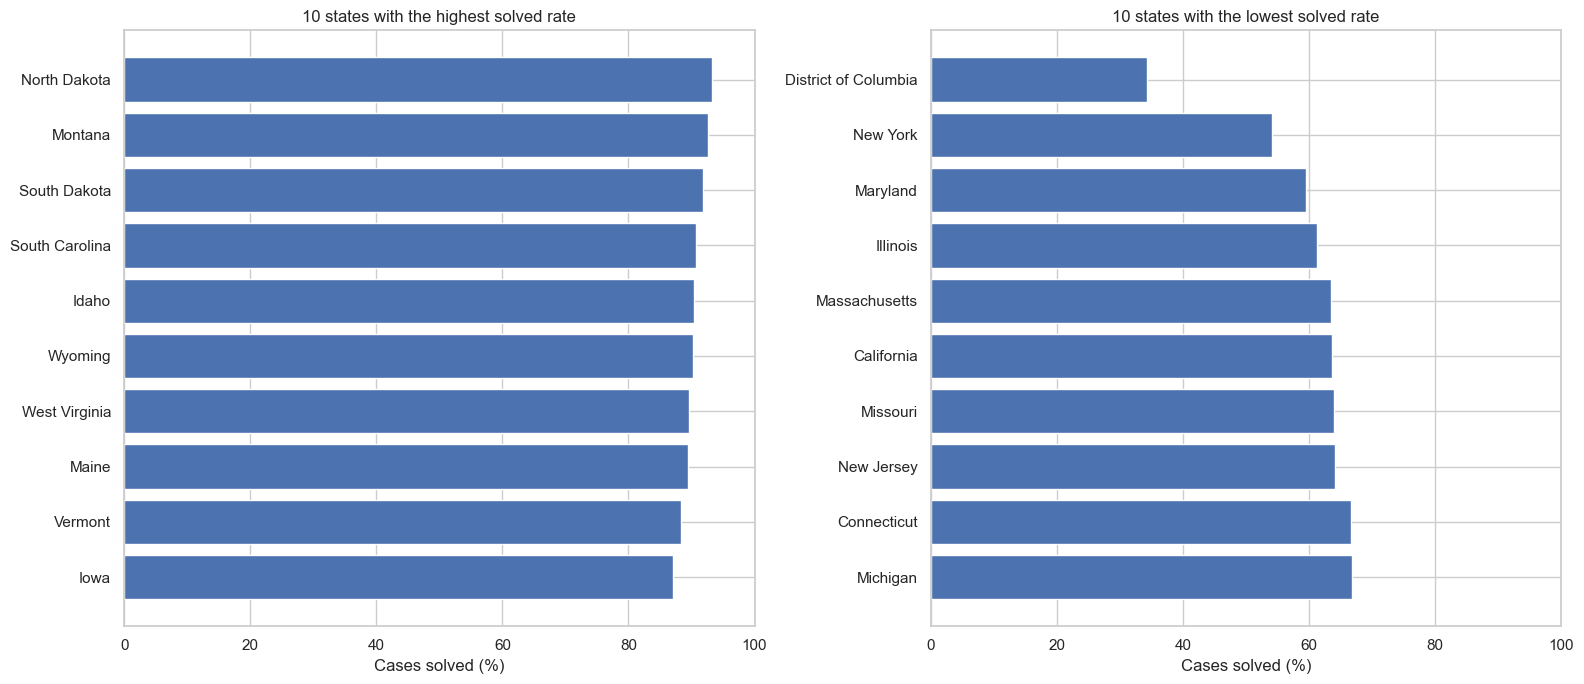

                Total_Cases  Solved_Cases  Solved_Rate
state                                                 
North Dakota            308           287        93.18
Montana                 601           557        92.68
South Dakota            442           406        91.86
South Carolina        11698         10618        90.77
Idaho                  1150          1040        90.43
Wyoming                 630           569        90.32
West Virginia          3061          2743        89.61
Maine                   869           777        89.41
Vermont                 412           364        88.35
Iowa                   1749          1524        87.14
                      Total_Cases  Solved_Cases  Solved_Rate
state                                                       
District of Columbia         7115          2441        34.31
New York                    49268         26656        54.10
Maryland                    17312         10308        59.54
Illinois                    25871  

In [17]:
known = df[df["crime_solved"].isin(["Yes", "No"])]
state_stats = known.groupby("state").agg(
    Total_Cases=("crime_solved", "size"),
    Solved_Cases=("crime_solved", lambda x: (x == "Yes").sum()),
)
state_stats["Solved_Rate"] = state_stats["Solved_Cases"] / state_stats["Total_Cases"] * 100
state_stats = state_stats[state_stats["Total_Cases"] >= 100]

best = state_stats.nlargest(10, "Solved_Rate").sort_values("Solved_Rate")
worst = state_stats.nsmallest(10, "Solved_Rate").sort_values("Solved_Rate", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, data, title in [(axes[0], best, "10 states with the highest solved rate"),
                        (axes[1], worst, "10 states with the lowest solved rate")]:
    ax.barh(data.index, data["Solved_Rate"])
    ax.set_title(title)
    ax.set_xlabel("Cases solved (%)")
    ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

print(best.sort_values("Solved_Rate", ascending=False).round(2))
print(worst.sort_values("Solved_Rate").round(2))

**Insight:** North Dakota (93.2%), Montana (92.7%) and South Dakota (91.9%) solve the highest share of cases. South Carolina, at 90.8%, is the best among large states (11,698 cases). The District of Columbia is lowest at 34.3%, then New York (54.1%), Maryland (59.5%) and Illinois (61.3%). The typical state solves 78.9%. California has the most cases and solves 63.6%, which is sixth lowest, but Texas, the second largest, solves 76.4%, so having lots of cases doesn't automatically mean a low solve rate. Small states have few cases, so their rates can swing more.

### 3.9 States with the most records: solved vs unsolved

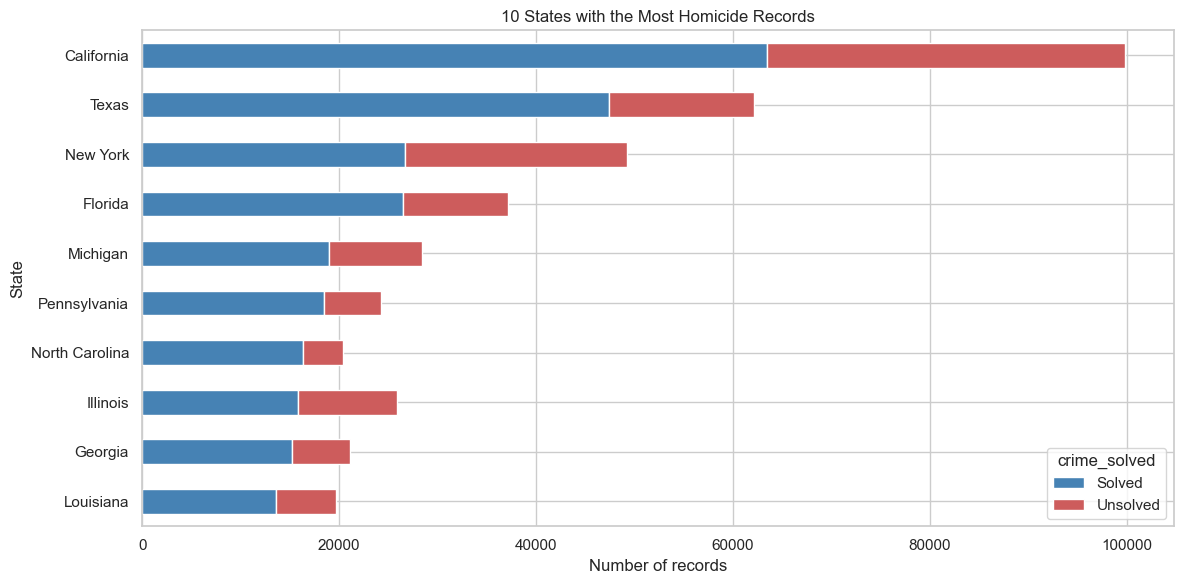

crime_solved,No,Yes,Total
state,,,
California,36369,63414,99783
Texas,14680,47415,62095
New York,22612,26656,49268
Florida,10647,26517,37164
Michigan,9434,19014,28448
Illinois,10026,15845,25871
Pennsylvania,5810,18426,24236
Georgia,5848,15240,21088
North Carolina,4036,16354,20390


In [18]:
state_cases = pd.crosstab(df["state"], df["crime_solved"])
state_cases["Total"] = state_cases.sum(axis=1)
top_states = state_cases.sort_values("Total", ascending=False).head(10)

top_states[["Yes", "No"]].rename(columns={"Yes": "Solved", "No": "Unsolved"}).sort_values(
    by="Solved", ascending=True
).plot(kind="barh", stacked=True, figsize=(12, 6), color=["steelblue", "indianred"])
plt.title("10 States with the Most Homicide Records")
plt.xlabel("Number of records")
plt.ylabel("State")
plt.tight_layout()
plt.show()
top_states

**Insight:** California has the most records (99,783), and 36,369 of them (36.4%) are unsolved. Texas has 62,095 with 23.6% unsolved, and New York has 49,268 with 45.9% unsolved. California and New York have the most unsolved cases overall. Texas has more records than New York but fewer unsolved ones (14,680 against 22,612).

### 3.10 Solved rate by weapon

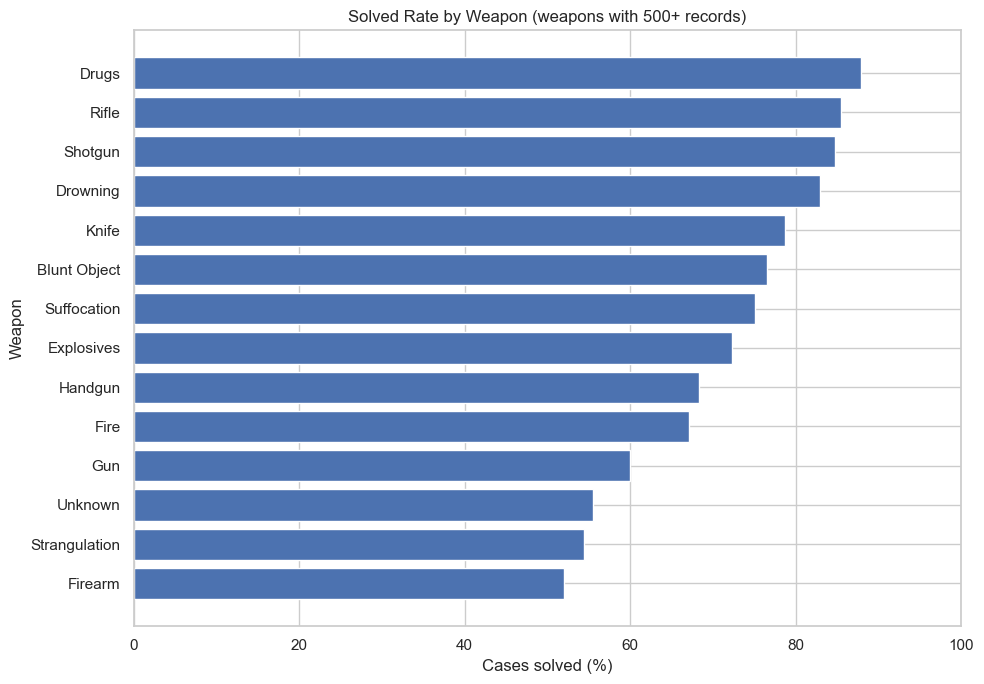

,Total_Cases,Solved_Cases,Solved_Rate
weapon,,,
Drugs,1588,1396,87.91
Rifle,23347,19946,85.43
Shotgun,30722,26040,84.76
Drowning,1204,999,82.97
Knife,94962,74758,78.72
Blunt Object,67337,51504,76.49
Suffocation,3968,2978,75.05
Explosives,537,388,72.25
Handgun,317484,216938,68.33


In [19]:
weapon_stats = df.groupby("weapon").agg(
    Total_Cases=("crime_solved", "size"),
    Solved_Cases=("crime_solved", lambda x: (x == "Yes").sum()),
)
weapon_stats["Solved_Rate"] = weapon_stats["Solved_Cases"] / weapon_stats["Total_Cases"] * 100
weapon_stats = weapon_stats[weapon_stats["Total_Cases"] >= 500].sort_values("Solved_Rate")

plt.figure(figsize=(10, 7))
plt.barh(weapon_stats.index, weapon_stats["Solved_Rate"])
plt.title("Solved Rate by Weapon (weapons with 500+ records)")
plt.xlabel("Cases solved (%)")
plt.ylabel("Weapon")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()
weapon_stats.sort_values("Solved_Rate", ascending=False).round(2)

**Insight:** Drugs (87.9%, but only 1,588 cases), rifles (85.4%) and shotguns (84.8%) have the highest solved rates. Handguns are by far the most common weapon (317,484 cases) and are solved 68.3% of the time. The lowest rates are for the general "Firearm" label (51.9%), strangulation (54.4%) and unknown weapons (55.5%). The data shows the differences between weapons, but not why they exist.